# Итоговая работа: audit-svc

Пащенко Дмитрий

## Подготовка стенда
Проверка доступных ресурсов и свободных портов:


In [1]:
%%bash
free -h | head -2
ss -ltn | grep -E ':(8929|8443|8088)\s' || echo "8929, 8443, 8088 свободны"

               total        used        free      shared  buff/cache   available
Mem:            14Gi       7.7Gi       1.9Gi       419Mi       6.0Gi       7.1Gi
8929, 8443, 8088 свободны


In [2]:
%%bash
cd repo/stands/Lecture4
./scripts/00-prereqs.sh 2>&1 | grep -vE 'Pulling|Waiting|Downloading|Extracting|Verifying|Download complete|Pull complete|Already exists' | tail -25


#11 [5/5] COPY entrypoint.sh /usr/local/bin/entrypoint.sh
#11 CACHED

#12 exporting to image
#12 exporting layers done
#12 exporting manifest sha256:16a507b63186cade28d79f3e108b07713cf8623af7cb8716eb7a5060b2efcc73 done
#12 exporting config sha256:d02a34fdbc4a6de8173e1adb30047a686b85e83877c1bde20d280ed6e8f70662 done
#12 exporting attestation manifest sha256:e16918f3dbe2e00a623aa7b6e9f9964336384edf2d61f2a0bf5c3d6466a4a85f done
#12 exporting manifest list sha256:69f2af9cf6784412f5602e44e3093d3a5e9243f3d4c9b9514228c4c528390ff9 done
#12 naming to docker.io/lecture4/deploy-vm:latest done
#12 unpacking to docker.io/lecture4/deploy-vm:latest done
#12 DONE 0.0s

#13 resolving provenance for metadata file
#13 DONE 0.0s
 Image lecture4/deploy-vm:latest Built 
gcr.io/kaniko-project/executor:v1.23.2-debug
docker.io/library/node:22-bookworm
docker.io/library/node:22-slim
docker.io/library/python:3.11-slim-bookworm
docker.io/library/alpine:3.22
docker.io/alpine/git:2.54.0
docker.io/library/nginx:1.28

## Этап А: запуск стенда


In [3]:
%%bash
cd repo/stands/Lecture4
./scripts/10-up.sh 2>&1 | grep -vE 'Pulling|Waiting|Downloading|Extracting|Verifying|Download complete|Pull complete|Already exists' | tail -20


 Container registryctl Started 
 Container harbor-db Started 
 Container redis Started 
 Container trivy-adapter Starting 
 Container harbor-core Starting 
 Container harbor-portal Started 
 Container trivy-adapter Started 
 Container harbor-core Started 
 Container harbor-jobservice Starting 
 Container nginx Starting 
 Container harbor-jobservice Started 
 Container nginx Started 
==> Жду: Harbor https://harbor.localtest.me:8443 (до 300 с)
==> Готово: Harbor https://harbor.localtest.me:8443 (5 с)
==> Жду: GitLab http://gitlab.localtest.me:8929 (первый старт — 3–5 минут) (до 900 с)
==> Готово: GitLab http://gitlab.localtest.me:8929 (первый старт — 3–5 минут) (141 с)

GitLab:  http://gitlab.localtest.me:8929        root / Zq8-Mirt-Volg-4417
Harbor:  https://harbor.localtest.me:8443      admin / Lab4-Harbor-2026
Первый раз после этого запустите scripts/20-bootstrap.sh


In [4]:
%%bash
cd repo/stands/Lecture4
./scripts/20-bootstrap.sh 2>&1 | tail -25

==> Проект demo/counter-deploy
==> Код → demo/counter-deploy (без запуска пайплайна)
==> Защищённые теги v* в counter-frontend
==> Защищённые теги v* в counter-backend
==> Harbor: проект demo (автосканирование при push)
==> Harbor: robot-аккаунт gitlab (push/pull в проекте demo)
==> Переменная группы HARBOR_ROBOT_USER (masked=false, protected=false)
==> Переменная группы HARBOR_ROBOT_SECRET (masked=true, protected=true)
==> Project access token ci-bot в counter-deploy (Maintainer, write_repository)
==> Переменная группы DEPLOY_TOKEN (masked=true, protected=true)
==> Общий раннер (instance, docker executor)
Runtime platform                                    arch=amd64 os=linux pid=31 revision=3c39fceb version=19.4.1
Running in system-mode.                            
                                                   
Verifying runner... is valid                        correlation_id=01M4XRX0PA8BRC0RRKQD7PSYMN runner=DoP6nPlmn runner_name=runner-docker
Runner registered successfully. F

In [5]:
%%bash
docker ps --format 'table {{.Names}}\t{{.Status}}' | grep -vE 'pd_log|nginx-letsencrypt|course'
free -h | head -2

NAMES                          STATUS
nginx                          Up 4 minutes (healthy)
harbor-jobservice              Up 4 minutes (healthy)
harbor-core                    Up 4 minutes (healthy)
trivy-adapter                  Up 4 minutes (healthy)
registry                       Up 4 minutes (healthy)
harbor-db                      Up 4 minutes (healthy)
registryctl                    Up 4 minutes (healthy)
harbor-portal                  Up 4 minutes (healthy)
redis                          Up 4 minutes (healthy)
harbor-log                     Up 4 minutes (healthy)
runner-docker                  Up 4 minutes
webhook-echo                   Up 4 minutes
gitlab                         Up 4 minutes (healthy)
deploy-vm                      Up 4 minutes
               total        used        free      shared  buff/cache   available
Mem:            14Gi        11Gi       197Mi       401Mi       4.0Gi       3.3Gi


## Проект audit-svc в GitLab
Создание проекта в группе `demo` через API:


In [6]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
group_id=$(gl GET /groups/demo | jq -r .id)
gl POST /projects \
    --data name=audit-svc --data "namespace_id=$group_id" \
    --data visibility=private --data default_branch=main \
  | jq '{id, path_with_namespace, default_branch, web_url}'

{
  "id": 5,
  "path_with_namespace": "demo/audit-svc",
  "default_branch": "main",
  "web_url": "http://gitlab.localtest.me:8929/demo/audit-svc"
}


In [7]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
gl POST "/projects/$(project_id audit-svc)/protected_tags" --data-urlencode 'name=v*' --data create_access_level=40 \
  | jq '{name, create_access_levels: [.create_access_levels[].access_level_description]}'

{
  "name": "v*",
  "create_access_levels": [
    "Maintainers"
  ]
}


## Задание 2: секреты в ansible-vault
Шифрование паролей БД через ansible-vault. Пароль от vault локально хранится в `.vault_pass` (добавлен в `.gitignore`), в CI передаётся через защищённую переменную `ANSIBLE_VAULT_PASSWORD`.


In [8]:
%%bash
cd final/deploy
umask 077
openssl rand -hex 16 > .vault_pass
vault=inventories/prom/group_vars/all/vault.yml
cat > "$vault" <<EOF
vault_postgres_superuser_password: "$(openssl rand -hex 16)"
vault_audit_svc_db_password: "$(openssl rand -hex 16)"
EOF
ansible-vault encrypt --vault-password-file .vault_pass "$vault"
chmod 644 "$vault"
ls -l .vault_pass "$vault"
head -3 "$vault"
ansible-vault view --vault-password-file .vault_pass "$vault" | cut -d: -f1

-rw-r--r-- 1 pd pd 873 Oct 14 20:56 inventories/prom/group_vars/all/vault.yml
-rw------- 1 pd pd  33 Oct 14 20:56 .vault_pass
$ANSIBLE_VAULT;1.1;AES256
32653531656132343731616339666534616332316635313530353663333735393634396162616239
3466373334306163653237303433363463313333316237630a636330616333363261656634363532
vault_postgres_superuser_password
vault_audit_svc_db_password


В CI пароль передаётся скриптом `vault-pass.sh` из переменной (Masked + Protected):


In [9]:
%%bash
cat final/deploy/vault-pass.sh
cd repo/stands/Lecture4
. scripts/lib.sh
gl POST "/projects/$(project_id audit-svc)/variables" \
    --data key=ANSIBLE_VAULT_PASSWORD \
    --data-urlencode "value=$(cat ../../../final/deploy/.vault_pass)" \
    --data raw=true --data masked=true --data protected=true \
  | jq '{key, masked, protected, raw}'
gl GET "/groups/demo/variables" | jq -r '.[] | "\(.key)  masked=\(.masked) protected=\(.protected)"'

#!/bin/sh
# передаём пароль для ansible-vault из CI-переменной ANSIBLE_VAULT_PASSWORD
set -eu
printf '%s\n' "${ANSIBLE_VAULT_PASSWORD:?ANSIBLE_VAULT_PASSWORD is not set}"
{
  "key": "ANSIBLE_VAULT_PASSWORD",
  "masked": true,
  "protected": true,
  "raw": true
}
HARBOR_ROBOT_USER  masked=false protected=false
HARBOR_ROBOT_SECRET  masked=true protected=true
DEPLOY_TOKEN  masked=true protected=true


## Деплой-раннер на deploy-vm
Регистрация раннера с тегами `deploy,prom` на целевой машине `deploy-vm`. Опция Protected - раннер берёт задачи только с защищённых тегов.


In [10]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
token=$(gl POST /user/runners \
    --data runner_type=project_type \
    --data "project_id=$(project_id audit-svc)" \
    --data "description=audit-svc deploy runner" \
    --data 'tag_list=deploy,prom' \
    --data run_untagged=false \
    --data access_level=ref_protected | jq -r .token)

docker exec deploy-vm bash -c '
    mkdir -p /data/gitlab-runner/builds /data/gitlab-runner/cache
    chown -R gitlab-runner:gitlab-runner /data/gitlab-runner
    chmod -R 0700 /data/gitlab-runner'

docker exec deploy-vm gitlab-runner register \
    --non-interactive \
    --url "$GITLAB_URL" \
    --token "$token" \
    --executor shell \
    --template-config /etc/gitlab-runner/template.toml 2>&1 | grep -v '^$'
docker exec deploy-vm gitlab-runner list 2>&1 | sed 's/glrt-[^ ]*/glrt-***/'
sleep 15
gl GET "/projects/$(project_id audit-svc)/runners" | jq -c '.[] | {id, description, status, is_shared}'

Runtime platform                                    arch=amd64 os=linux pid=338 revision=3c39fceb version=19.4.1
Running in system-mode.                            
                                                   
Merging configuration from template file "/etc/gitlab-runner/template.toml" 
Verifying runner... is valid                        correlation_id=01M4XRXK9B80YANNKNE7AYXT42 runner=SUiDYAsz9 runner_name=deploy-vm
Runner registered successfully. Feel free to start it, but if it's running already the config should be automatically reloaded!
 
Configuration (with the authentication token) was saved in "/etc/gitlab-runner/config.toml" 
Runtime platform                                    arch=amd64 os=linux pid=362 revision=3c39fceb version=19.4.1
Listing configured runners                          ConfigFile=/etc/gitlab-runner/config.toml
deploy-vm                                           Executor=shell Token=glrt-*** URL=http://gitlab.localtest.me:8929
{"id":1,"description":"ru

Проверка окружения Ansible на `deploy-vm`:


In [11]:
%%bash
docker exec deploy-vm bash -c 'apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq --no-install-recommends ansible python3-psycopg2 python3-requests >/dev/null && echo "installed"'
docker exec deploy-vm install -d -o gitlab-runner -g gitlab-runner /data/audit-svc
docker exec -u gitlab-runner deploy-vm ansible --version | head -2
docker exec -u gitlab-runner deploy-vm ansible-galaxy collection list 2>/dev/null | grep -E 'community\.(docker|postgresql) '

debconf: delaying package configuration, since apt-utils is not installed


installed
ansible [core 2.16.3]
  config file = None
community.docker                         3.7.0  
community.postgresql                     3.3.0  


## Задание 1: пайплайн на main
Публикация проекта `final/` в ветку `main` репозитория `demo/audit-svc`:


In [12]:
%%bash
cd final
git init --quiet --initial-branch main
git add --all
git status --short
echo "---"
git check-ignore -v deploy/.vault_pass
head -1 deploy/inventories/prom/group_vars/all/vault.yml

A  .dockerignore
A  .editorconfig
A  .gitignore
A  .gitlab-ci.yml
A  Dockerfile
A  README.md
A  deploy/ansible.cfg
A  deploy/audit-svc.play.yml
A  deploy/inventories/prom/group_vars/all/main.yml
A  deploy/inventories/prom/group_vars/all/vault.yml
A  deploy/inventories/prom/hosts.yaml
A  deploy/requirements.yml
A  deploy/templates/config.yaml.j2
A  deploy/templates/nginx.conf.j2
A  deploy/vault-pass.sh
A  monitoring/compose.yaml
A  monitoring/prometheus/prometheus.yml
A  poetry.lock
A  pyproject.toml
A  src/audit_svc/__init__.py
A  src/audit_svc/__main__.py
A  src/audit_svc/config.py
A  src/audit_svc/generate.py
A  src/audit_svc/main.py
A  src/audit_svc/metrics.py
A  src/audit_svc/migrate.py
A  src/audit_svc/migrations/0001_create_events.sql
A  src/audit_svc/migrations/0002_events_app_index.sql
A  src/audit_svc/storage.py
A  tests/__init__.py
A  tests/conftest.py
A  tests/test_main.py
---
.gitignore:24:deploy/.vault_pass	deploy/.vault_pass
$ANSIBLE_VAULT;1.1;AES256


In [13]:
%%bash
cd final
git commit --quiet -m "audit-svc: Dockerfile, CI, deploy, monitoring"
git log --oneline
cd ../repo/stands/Lecture4
. scripts/lib.sh
git -C ../../../final remote add origin "$(git_remote_url audit-svc)"
git -C ../../../final push --set-upstream origin main 2>&1 | sed "s/$(gitlab_token)/***/g"
./scripts/pipeline-status.sh audit-svc 1200

5121976 audit-svc: Dockerfile, CI, deploy, monitoring
To http://gitlab.localtest.me:8929/demo/audit-svc.git
 * [new branch]      main -> main
branch 'main' set up to track 'origin/main'.


==> audit-svc: пайплайн #5 — success (http://gitlab.localtest.me:8929/demo/audit-svc/-/pipelines/5)


  success   test  Run Tests  (54 s)
  success   publish  Publish Image  (44 s)


Тесты (JUnit):

In [14]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?per_page=1" | jq -r '.[0].id')
gl GET "/projects/$pid/pipelines/$pipeline" | jq -c '{id, ref, status}'
gl GET "/projects/$pid/pipelines/$pipeline/test_report_summary" | jq -c '.total'

{"id":5,"ref":"main","status":"success"}
{"time":0.041,"count":6,"success":6,"failed":0,"skipped":0,"error":0,"suite_error":null}


Лог публикации:

In [15]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?per_page=1" | jq -r '.[0].id')
job=$(gl GET "/projects/$pid/pipelines/$pipeline/jobs" | jq -r '.[] | select(.name=="Publish Image") | .id')
gl GET "/projects/$pid/jobs/$job/trace" | sed -E 's/\r$//; s/\x1b\[[0-9;]*[mK]//g; s/^[0-9-]+T[0-9:.]+Z [0-9a-f]{2}[OE]\+? ?//' \
  | grep -E '^\$ |Pushing|Pushed|pushed|Job succeeded|ERROR'
echo "секрет робота в логе: $(gl GET "/projects/$pid/jobs/$job/trace" | grep -c "$(jq -r .secret .state/harbor-robot.json)")"

$ set -eu
$ b64_auth=$(printf '%s:%s' "$HARBOR_ROBOT_USER" "$HARBOR_ROBOT_SECRET" | base64 | tr -d '\n')
$ printf '{"auths": {"%s": {"auth": "%s"}}}' "$HARBOR_HOST" "$b64_auth" >/kaniko/.docker/config.json
$ /kaniko/executor --reproducible --context "$CI_PROJECT_DIR" --dockerfile "$CI_PROJECT_DIR/Dockerfile" --destination "$HARBOR_IMAGE:$IMAGE_TAG" --digest-file image.digest
INFO[0040] Pushing image to harbor.localtest.me:8443/demo/audit-svc:main_51219762 
INFO[0041] Pushed harbor.localtest.me:8443/demo/audit-svc@sha256:7aed263bc47c13890305567db577547e46d8cbf319ab6d1b193b526f43882a36 
$ echo "pushed $HARBOR_IMAGE:$IMAGE_TAG@$(cat image.digest)"
pushed harbor.localtest.me:8443/demo/audit-svc:main_51219762@sha256:7aed263bc47c13890305567db577547e46d8cbf319ab6d1b193b526f43882a36
Job succeeded
секрет робота в логе: 0


### Пайплайн main
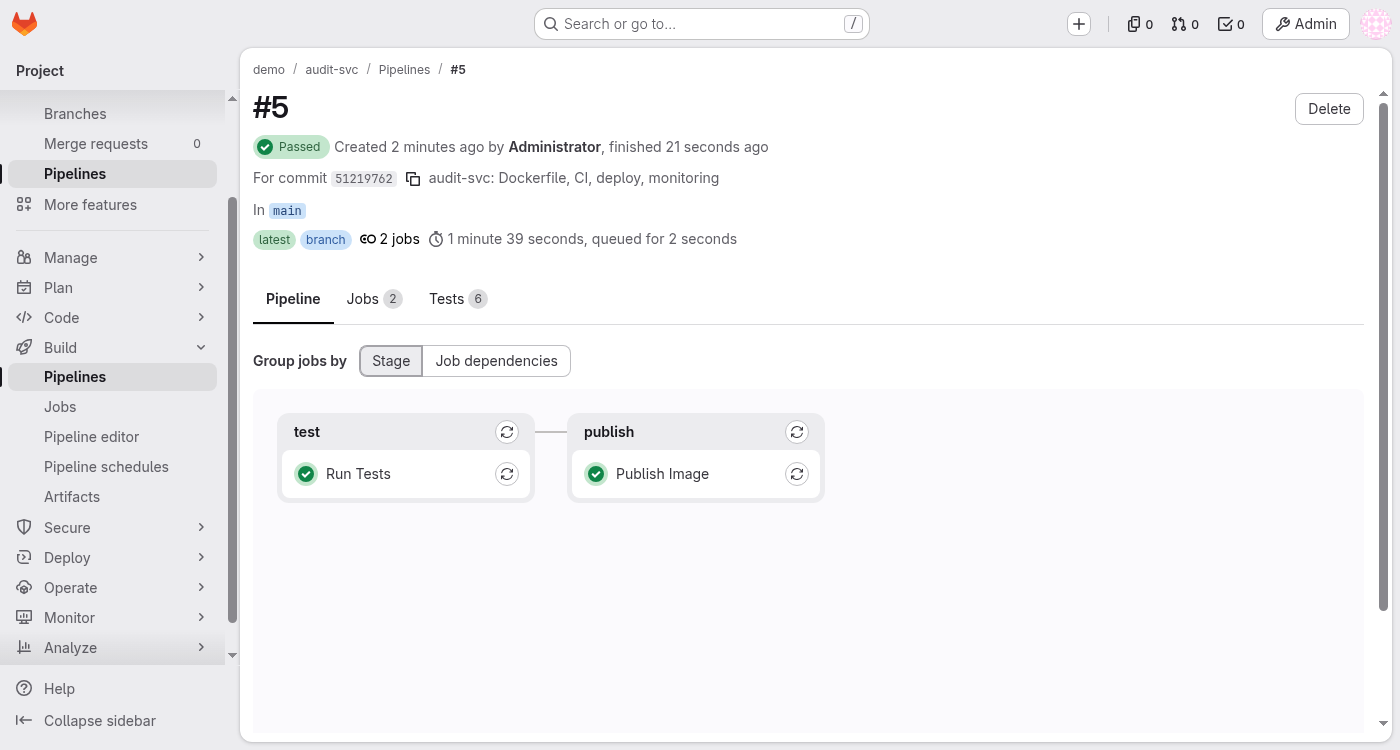


### Образ в Harbor
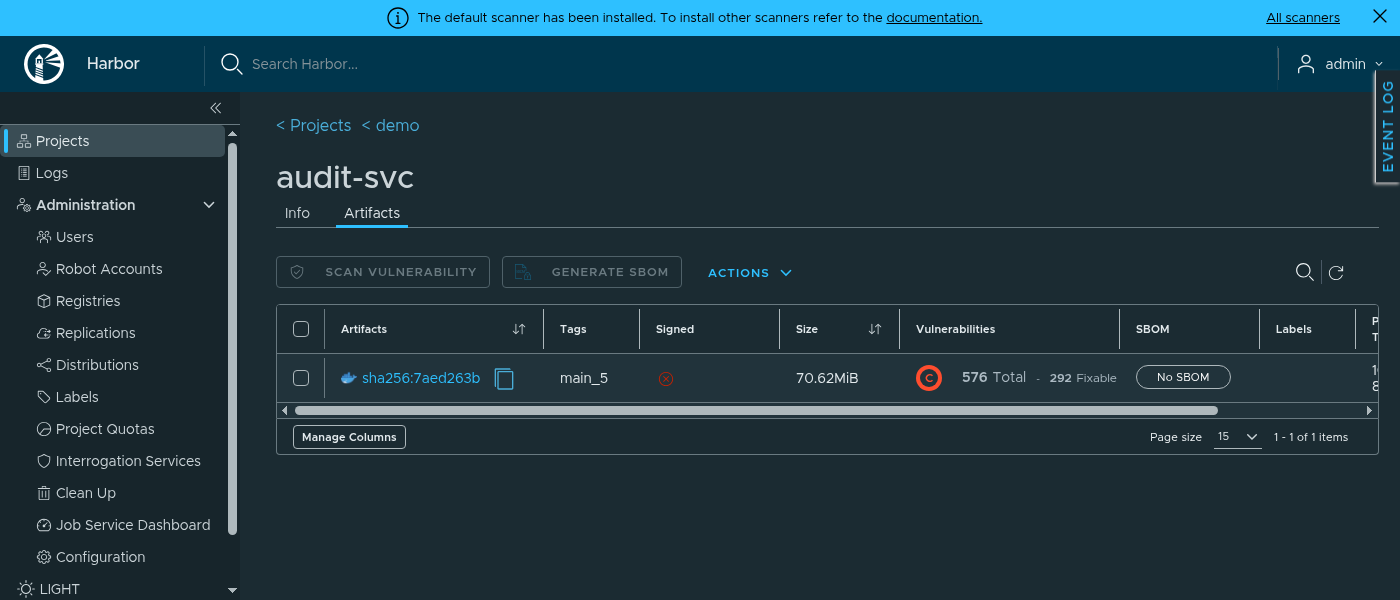


## Задания 1.3 и 3: тег v1.0.0 → развёртывание сервиса
Сборка образа с версионным тегом `v1.0.0` и запуск задачи `Deploy` на deploy-vm:


In [16]:
%%bash
cd final
git tag v1.0.0
git push origin v1.0.0 2>&1 | grep -v '^remote:'
cd ../repo/stands/Lecture4
sleep 5
./scripts/pipeline-status.sh audit-svc 1500

To http://gitlab.localtest.me:8929/demo/audit-svc.git
 * [new tag]         v1.0.0 -> v1.0.0


==> audit-svc: пайплайн #6 — success (http://gitlab.localtest.me:8929/demo/audit-svc/-/pipelines/6)


  success   test  Run Tests  (14 s)
  success   publish  Publish Image  (46 s)
  success   deploy  Deploy  (37 s)


Полный лог деплоя:

In [17]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?ref=v1.0.0&per_page=1" | jq -r '.[0].id')
job=$(gl GET "/projects/$pid/pipelines/$pipeline/jobs" | jq -r '.[] | select(.name=="Deploy") | .id')
echo "pipeline $pipeline, job $job"
gl GET "/projects/$pid/jobs/$job/trace" | sed -E 's/\r$//; s/\x1b\[[0-9;]*[mK]//g; s/^[0-9-]+T[0-9:.]+Z [0-9a-f]{2}[OE]\+? ?//' > /tmp/deploy_v1.0.0.log
cat /tmp/deploy_v1.0.0.log

pipeline 6, job 5
Running with gitlab-runner 19.4.1 (3c39fceb)
  on deploy-vm SUiDYAsz9, system ID: r_5uvncVYfI01P
  UUID: 01a13b8e-cc17-75f4-b89f-874282658b4e
section_start:1792000868:prepare_executor
Preparing the "shell" executor
Using Shell (bash) executor...
section_end:1792000868:prepare_executor
section_start:1792000868:prepare_script
Preparing environment
Running on deploy-vm...
section_end:1792000868:prepare_script
section_start:1792000868:get_sources
Getting source from Git repository
Gitaly correlation ID: 01M4XS6G097XG20PJ5QVW1TE8Y
Fetching changes with git depth set to 20...
Initialized empty Git repository in /data/gitlab-runner/builds/SUiDYAsz9/0/demo/audit-svc/.git/
Created fresh repository.
Checking out 51219762 as detached HEAD (ref is v1.0.0)...
Skipping Git submodules setup
section_end:1792000868:get_sources
section_start:1792000868:download_artifacts
Runtime platform                                    arch=amd64 os=linux pid=1255 revision=3c39fceb version=19.4.1
se

In [18]:
%%bash
cd final/deploy
for key in vault_postgres_superuser_password vault_audit_svc_db_password; do
    pass=$(ansible-vault view --vault-password-file .vault_pass inventories/prom/group_vars/all/vault.yml | grep "^$key:" | cut -d'"' -f2)
    echo "$key: $(grep -c "$pass" /tmp/deploy_v1.0.0.log)"
done
echo "vault password: $(grep -c "$(cat .vault_pass)" /tmp/deploy_v1.0.0.log)"

vault_postgres_superuser_password: 0
vault_audit_svc_db_password: 0
vault password: 0


### Пайплайн тега v1.0.0
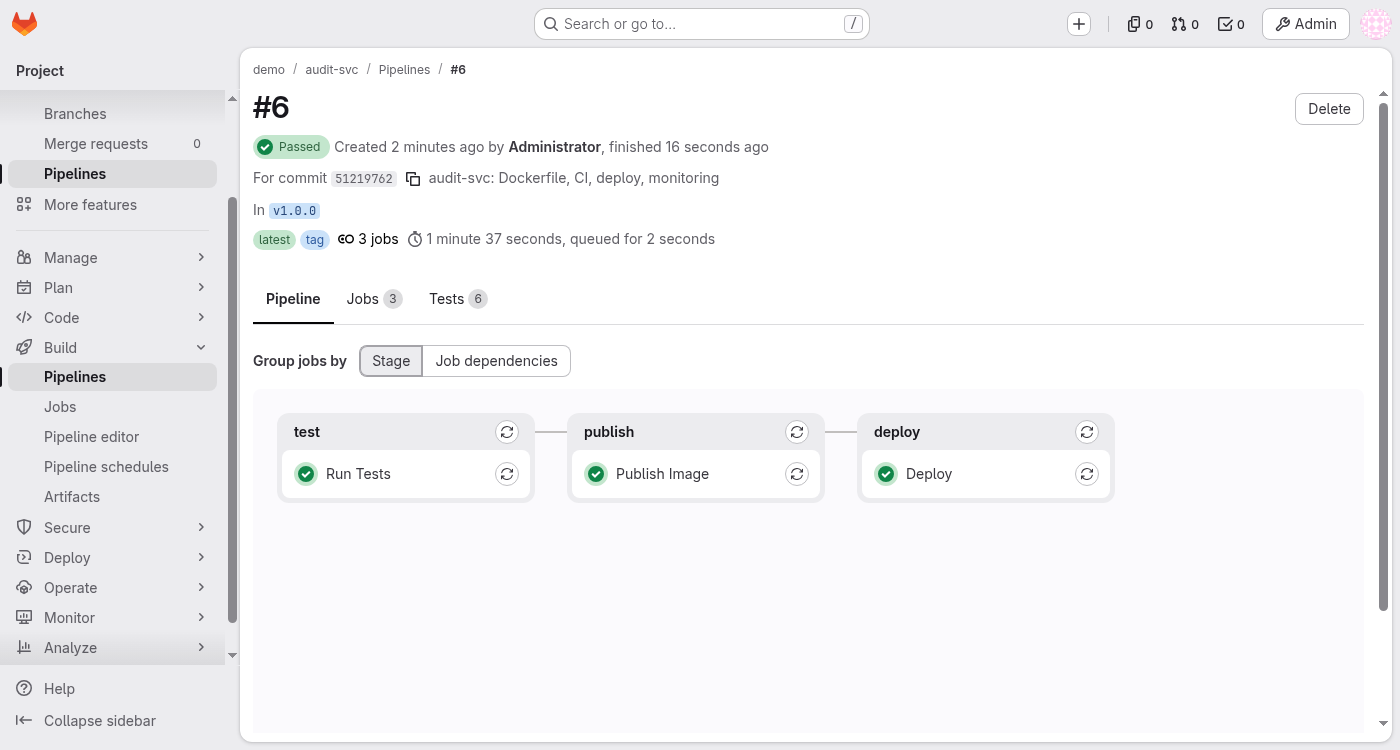


### Окружение prom
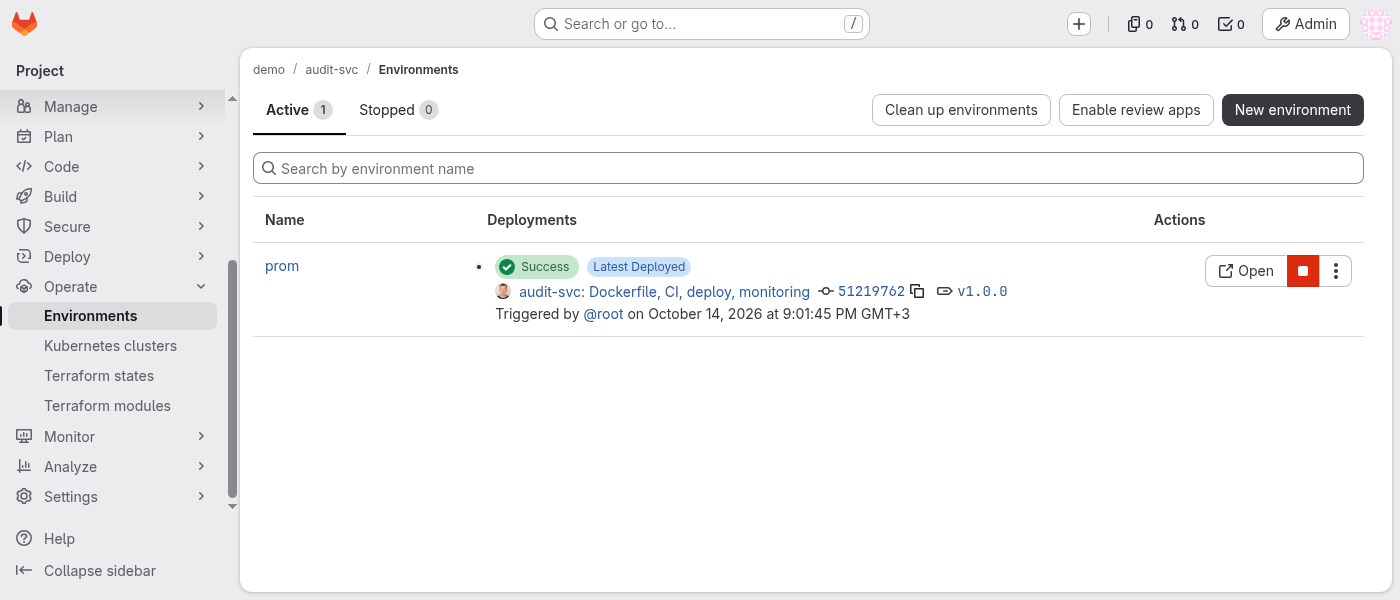


Порты только у nginx и exporter, конфиг 0640 (сервис читает его через доп. группу).

In [19]:
%%bash
docker exec deploy-vm docker ps --format 'table {{.Names}}\t{{.Image}}\t{{.Ports}}'
docker exec deploy-vm ls -l /data/audit-svc/config
docker exec deploy-vm docker exec audit-svc id
docker exec deploy-vm docker volume ls
docker exec deploy-vm docker network inspect audit -f '{{range .Containers}}{{.Name}} {{end}}'

NAMES                  IMAGE                                            PORTS
audit-nginx-exporter   nginx/nginx-prometheus-exporter:1.4              0.0.0.0:9113->9113/tcp
audit-nginx            nginx:1.28-alpine                                80/tcp, 0.0.0.0:8080->8080/tcp
audit-svc              harbor.localtest.me:8443/demo/audit-svc:v1.0.0   8080/tcp
audit-postgres         postgres:17                                      5432/tcp
total 4
-rw-r----- 1 gitlab-runner gitlab-runner 147 Oct 14 18:01 config.yaml
uid=1001(audit) gid=1001(audit) groups=1001(audit),100(users),998
DRIVER    VOLUME NAME
local     audit-postgres-data
audit-nginx-exporter audit-postgres audit-nginx audit-svc 


In [20]:
%%bash
curl -s localhost:8088/healthz; echo
curl -s -X POST localhost:8088/api/events -H 'Content-Type: application/json' \
     -d '{"app": "billing", "action": "login", "actor": "user1"}'; echo
curl -s 'localhost:8088/api/events?limit=5' | jq -c '.events[] | {app, action, actor}'

{"status": "ok"}
{"id": 1}
{"app":"billing","action":"login","actor":"user1"}


In [21]:
%%bash
docker exec deploy-vm docker exec audit-postgres psql -U postgres -c '\l audit' -c '\du audit_svc'
docker exec deploy-vm docker exec audit-postgres psql -U postgres -d audit -c '\dt' -c 'select * from schema_migrations'

                                                 List of databases
 Name  |   Owner   | Encoding | Locale Provider |  Collate   |   Ctype    | Locale | ICU Rules | Access privileges 
-------+-----------+----------+-----------------+------------+------------+--------+-----------+-------------------
 audit | audit_svc | UTF8     | libc            | en_US.utf8 | en_US.utf8 |        |           | 
(1 row)

     List of roles
 Role name | Attributes 
-----------+------------
 audit_svc | 

               List of relations
 Schema |       Name        | Type  |   Owner   
--------+-------------------+-------+-----------
 public | events            | table | audit_svc
 public | schema_migrations | table | audit_svc
(2 rows)

        version        |          applied_at           
-----------------------+-------------------------------
 0001_create_events    | 2026-10-14 18:01:33.620195+00
 0002_events_app_index | 2026-10-14 18:01:33.623473+00
(2 rows)



### 3.4 идемпотентность: Retry задачи Deploy
Должно быть `changed=0`.

In [22]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
started_before=$(docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?ref=v1.0.0&per_page=1" | jq -r '.[0].id')
job=$(gl GET "/projects/$pid/pipelines/$pipeline/jobs" | jq -r '.[] | select(.name=="Deploy") | .id')
new_job=$(gl POST "/projects/$pid/jobs/$job/retry" | jq -r .id)
echo "retry: job $job -> job $new_job"
until [[ "$(gl GET "/projects/$pid/jobs/$new_job" | jq -r .status)" =~ ^(success|failed|canceled)$ ]]; do sleep 10; done
gl GET "/projects/$pid/jobs/$new_job/trace" \
  | sed -E 's/\r$//; s/\x1b\[[0-9;]*[mK]//g; s/^[0-9-]+T[0-9:.]+Z [0-9a-f]{2}[OE]\+? ?//' \
  | grep -E '^(TASK|RUNNING HANDLER|changed|PLAY RECAP|deploy-vm +:)'
echo "StartedAt до:    $started_before"
echo "StartedAt после: $(docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc)"

retry: job 5 -> job 6
TASK [Gathering Facts] *********************************************************
TASK [Check that image is set] *************************************************
TASK [Create docker network] ***************************************************
TASK [Create postgres volume] **************************************************
TASK [Create config directories] ***********************************************
TASK [Start PostgreSQL] ********************************************************
TASK [Wait for PostgreSQL to become healthy] ***********************************
TASK [Remember PostgreSQL address] *********************************************
TASK [Create database user] ****************************************************
TASK [Create database] *********************************************************
TASK [Render audit-svc config] *************************************************
TASK [Pull audit-svc image] ****************************************************
TASK [

## Задание 4: Nginx и nginx-exporter
Проксирование запросов к сервису: открыты только маршруты `/api/`, `/healthz` и `/metrics`, остальные пути возвращают 404. Метрики `stub_status` доступны на отдельном порту 8081.


In [23]:
%%bash
before=$(docker exec deploy-vm docker logs audit-svc 2>&1 | grep -c 'config reload')
echo "'config reload' в логе сервиса до: $before"
curl -s localhost:8088/healthz; echo
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088/reload
curl -s -o /dev/null -w '%{http_code}\n' -X POST 'localhost:8088/reload?x=1'
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088//reload
curl -s -o /dev/null -w '%{http_code}\n' -X POST localhost:8088/%72eload
echo "'config reload' после: $(docker exec deploy-vm docker logs audit-svc 2>&1 | grep -c 'config reload')"
docker exec deploy-vm docker ps --format '{{.Names}}\t{{.Ports}}'

'config reload' в логе сервиса до: 1
{"status": "ok"}
404
404
404
404
'config reload' после: 1
audit-nginx-exporter	0.0.0.0:9113->9113/tcp
audit-nginx	80/tcp, 0.0.0.0:8080->8080/tcp
audit-svc	8080/tcp
audit-postgres	5432/tcp


In [24]:
%%bash
curl -s -o /dev/null -w 'localhost:8088/stub_status -> %{http_code}\n' localhost:8088/stub_status
docker exec deploy-vm docker exec audit-nginx wget -qO- http://127.0.0.1:8081/stub_status
docker exec deploy-vm curl -s localhost:9113/metrics | grep -E '^nginx_up'

localhost:8088/stub_status -> 404
Active connections: 2 
server accepts handled requests
 14 14 14 
Reading: 0 Writing: 1 Waiting: 1 
nginx_up 1


## Задание 3.3: смена пароля без перезапуска сервиса
Фиксация времени старта контейнера (`StartedAt`), смена пароля в `vault.yml`, коммит и выпуск тега `v1.0.1`:


In [25]:
%%bash
docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc | tee /tmp/started_before
curl -s localhost:8088/metrics | grep '^audit_config_reloads_total'

2026-10-14T18:01:34.125872917Z
audit_config_reloads_total{result="success"} 1.0


In [26]:
%%bash
cd final/deploy
vault=inventories/prom/group_vars/all/vault.yml
md5sum "$vault"
EDITOR="sed -i -E 's/^(vault_audit_svc_db_password: ).*/\1\"$(openssl rand -hex 16)\"/'" \
    ansible-vault edit --vault-password-file .vault_pass "$vault"
md5sum "$vault"
cd ..
git commit --quiet -am "deploy: rotate audit_svc database password"
git push 2>&1 | grep -v '^remote:'
git tag v1.0.1
git push origin v1.0.1 2>&1 | grep -v '^remote:'
cd ../repo/stands/Lecture4
sleep 5
./scripts/pipeline-status.sh audit-svc 1500

96d87f73cb0343e5fc67c3aca444acab  inventories/prom/group_vars/all/vault.yml
9f2eb77eee637888ddcd584fa58de896  inventories/prom/group_vars/all/vault.yml
To http://gitlab.localtest.me:8929/demo/audit-svc.git
   5121976..1f9c01c  main -> main
To http://gitlab.localtest.me:8929/demo/audit-svc.git
 * [new tag]         v1.0.1 -> v1.0.1


==> audit-svc: пайплайн #8 — success (http://gitlab.localtest.me:8929/demo/audit-svc/-/pipelines/8)


  success   test  Run Tests  (46 s)
  success   publish  Publish Image  (46 s)
  success   deploy  Deploy  (8 s)


Применение изменений: обновлены пароль в БД и конфигурационный файл, сработал хендлер reload. Контейнер сервиса не перезапускался (`Start audit-svc` - ok):


In [27]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?ref=v1.0.1&per_page=1" | jq -r '.[0].id')
job=$(gl GET "/projects/$pid/pipelines/$pipeline/jobs" | jq -r '.[] | select(.name=="Deploy") | .id')
echo "pipeline $pipeline, job $job"
gl GET "/projects/$pid/jobs/$job/trace" \
  | sed -E 's/\r$//; s/\x1b\[[0-9;]*[mK]//g; s/^[0-9-]+T[0-9:.]+Z [0-9a-f]{2}[OE]\+? ?//' \
  | grep -E '^(TASK|RUNNING HANDLER|ok:|changed:|PLAY RECAP|deploy-vm +:)|"(status|changed)"|applied'

pipeline 8, job 11
TASK [Gathering Facts] *********************************************************
ok: [deploy-vm]
TASK [Check that image is set] *************************************************
ok: [deploy-vm] => {
    "changed": false,
TASK [Create docker network] ***************************************************
ok: [deploy-vm]
TASK [Create postgres volume] **************************************************
ok: [deploy-vm]
TASK [Create config directories] ***********************************************
ok: [deploy-vm] => (item=/data/audit-svc/config)
ok: [deploy-vm] => (item=/data/audit-svc/nginx)
TASK [Start PostgreSQL] ********************************************************
ok: [deploy-vm]
TASK [Wait for PostgreSQL to become healthy] ***********************************
ok: [deploy-vm]
TASK [Remember PostgreSQL address] *********************************************
ok: [deploy-vm]
TASK [Create database user] ****************************************************
changed: [deploy

In [28]:
%%bash
echo "StartedAt до:    $(cat /tmp/started_before)"
echo "StartedAt после: $(docker exec deploy-vm docker inspect -f '{{.State.StartedAt}}' audit-svc)"
docker exec deploy-vm docker logs audit-svc 2>&1 | grep 'config reload'
curl -s localhost:8088/metrics | grep '^audit_config_reloads_total'
curl -s -w '  -> %{http_code}\n' localhost:8088/healthz
curl -s -X POST localhost:8088/api/events -H 'Content-Type: application/json' -d '{"app": "billing", "action": "after-rotation", "actor": "user1"}'; echo
cd repo/stands/Lecture4
. scripts/lib.sh
hb GET "/projects/demo/repositories/audit-svc/artifacts?with_tag=true" | jq -c '.[] | {digest: .digest[0:19], tags: [.tags[].name]}'

StartedAt до:    2026-10-14T18:01:34.125872917Z
StartedAt после: 2026-10-14T18:01:34.125872917Z
2026-10-14 18:01:44,450 [INFO] audit_svc.main: config reloaded, database settings are unchanged
2026-10-14 18:05:06,029 [INFO] audit_svc.main: config reloaded, reconnected to the database
audit_config_reloads_total{result="success"} 2.0
{"status": "ok"}  -> 200
{"id": 2}
{"digest":"sha256:7aed263bc47c","tags":["v1.0.1","main_1f9c01cb","v1.0.0","main_51219762"]}


## Дополнительное задание: миграции при каждом развёртывании
Задача `migrate` в плейбуке запускается перед стартом сервиса. При ошибке миграции развёртывание останавливается.

Добавление миграции `0003_events_actor_index.sql` и публикация тега `v1.1.0`:


In [29]:
%%bash
cd final
cat > src/audit_svc/migrations/0003_events_actor_index.sql <<'EOF'
-- поиск событий конкретного пользователя: WHERE actor = ...
CREATE INDEX IF NOT EXISTS events_actor_idx ON events (actor);
EOF
git add src/audit_svc/migrations/0003_events_actor_index.sql
git commit --quiet -m "migrations: 0003 index on events.actor"
git push 2>&1 | grep -v '^remote:'
git tag v1.1.0
git push origin v1.1.0 2>&1 | grep -v '^remote:'
cd ../repo/stands/Lecture4
sleep 5
./scripts/pipeline-status.sh audit-svc 1500

To http://gitlab.localtest.me:8929/demo/audit-svc.git
   1f9c01c..eb5b0a3  main -> main
To http://gitlab.localtest.me:8929/demo/audit-svc.git
 * [new tag]         v1.1.0 -> v1.1.0


==> audit-svc: пайплайн #10 — success (http://gitlab.localtest.me:8929/demo/audit-svc/-/pipelines/10)


  success   test  Run Tests  (14 s)
  success   publish  Publish Image  (51 s)
  success   deploy  Deploy  (8 s)


In [30]:
%%bash
cd repo/stands/Lecture4
. scripts/lib.sh
pid=$(project_id audit-svc)
pipeline=$(gl GET "/projects/$pid/pipelines?ref=v1.1.0&per_page=1" | jq -r '.[0].id')
job=$(gl GET "/projects/$pid/pipelines/$pipeline/jobs" | jq -r '.[] | select(.name=="Deploy") | .id')
echo "pipeline $pipeline, job $job"
gl GET "/projects/$pid/jobs/$job/trace" \
  | sed -E 's/\r$//; s/\x1b\[[0-9;]*[mK]//g; s/^[0-9-]+T[0-9:.]+Z [0-9a-f]{2}[OE]\+? ?//' \
  | grep -E '^(TASK|RUNNING HANDLER|ok:|changed:|PLAY RECAP|deploy-vm +:)|applying|applied'

pipeline 10, job 16
TASK [Gathering Facts] *********************************************************
ok: [deploy-vm]
TASK [Check that image is set] *************************************************
ok: [deploy-vm] => {
TASK [Create docker network] ***************************************************
ok: [deploy-vm]
TASK [Create postgres volume] **************************************************
ok: [deploy-vm]
TASK [Create config directories] ***********************************************
ok: [deploy-vm] => (item=/data/audit-svc/config)
ok: [deploy-vm] => (item=/data/audit-svc/nginx)
TASK [Start PostgreSQL] ********************************************************
ok: [deploy-vm]
TASK [Wait for PostgreSQL to become healthy] ***********************************
ok: [deploy-vm]
TASK [Remember PostgreSQL address] *********************************************
ok: [deploy-vm]
TASK [Create database user] ****************************************************
ok: [deploy-vm]
TASK [Create database

In [31]:
%%bash
docker exec deploy-vm docker exec audit-postgres psql -U postgres -d audit -c 'select * from schema_migrations' -c '\di'
docker exec deploy-vm docker ps --format '{{.Names}}\t{{.Image}}\t{{.Status}}'

         version         |          applied_at           
-------------------------+-------------------------------
 0001_create_events      | 2026-10-14 18:01:33.620195+00
 0002_events_app_index   | 2026-10-14 18:01:33.623473+00
 0003_events_actor_index | 2026-10-14 18:06:49.290263+00
(3 rows)

                              List of relations
 Schema |            Name            | Type  |   Owner   |       Table       
--------+----------------------------+-------+-----------+-------------------
 public | events_actor_idx           | index | audit_svc | events
 public | events_app_received_at_idx | index | audit_svc | events
 public | events_pkey                | index | audit_svc | events
 public | schema_migrations_pkey     | index | audit_svc | schema_migrations
(4 rows)

audit-svc	harbor.localtest.me:8443/demo/audit-svc:v1.1.0	Up 7 seconds
audit-nginx-exporter	nginx/nginx-prometheus-exporter:1.4	Up 5 minutes
audit-nginx	nginx:1.28-alpine	Up 5 minutes
audit-postgres	postgres:17	Up 5

## Этап Б: мониторинг (задание 5)
Остановка GitLab и Harbor для освобождения ресурсов, на `deploy-vm` остаются сервис и Nginx:


In [32]:
%%bash
cd repo/stands/Lecture4
docker stop gitlab runner-docker webhook-echo
docker stop $(docker ps -q --filter label=com.docker.compose.project=harbor) > /dev/null
docker ps --format '{{.Names}}\t{{.Status}}' | grep -vE 'pd_log|nginx-letsencrypt|course'
free -h | head -2

gitlab
runner-docker
webhook-echo
deploy-vm	Up 15 minutes
               total        used        free      shared  buff/cache   available
Mem:            14Gi       7.4Gi       5.0Gi        89Mi       2.9Gi       7.4Gi


Стек мониторинга в сети `lab`. Сбор метрик сервиса выполняется через Nginx:


In [33]:
%%bash
cd final/monitoring
cat prometheus/prometheus.yml
docker compose up -d 2>&1 | grep -v Pulling
sleep 40
curl -s localhost:9090/api/v1/targets | jq -r '.data.activeTargets[] | "\(.labels.job)\t\(.scrapeUrl)\t\(.health)"'

global:
  scrape_interval: 15s
  evaluation_interval: 15s

scrape_configs:
  - job_name: prometheus
    static_configs:
      - targets: [localhost:9090]

  # сбор метрик сервиса через nginx (сам сервис портов наружу не публикует)
  - job_name: audit-svc
    metrics_path: /metrics
    static_configs:
      - targets: [deploy-vm:8080]
        labels:
          instance: deploy-vm

  - job_name: nginx
    static_configs:
      - targets: [deploy-vm:9113]
        labels:
          instance: deploy-vm
 Volume audit-monitoring_grafana-data Creating 
 Volume audit-monitoring_grafana-data Creating 
 Volume audit-monitoring_prometheus-data Creating 
 Volume audit-monitoring_prometheus-data Creating 
 Volume audit-monitoring_grafana-data Created 
 Volume audit-monitoring_grafana-data Created 
 Container audit-monitoring-grafana-1 Creating 
 Volume audit-monitoring_prometheus-data Created 
 Volume audit-monitoring_prometheus-data Created 
 Container audit-monitoring-prometheus-1 Creating 
 Conta

Запуск фоновой генерации нагрузки на 11 минут:


In [34]:
%%bash
docker exec deploy-vm docker run -d --rm --name audit-generate --network audit \
    harbor.localtest.me:8443/demo/audit-svc:v1.1.0 generate --url http://audit-nginx:8080 --duration 660
sleep 5
docker exec deploy-vm docker logs audit-generate 2>&1 | tail -3

4d7225f5a902426afb1b0ef27f2158fd1391f2ad3a423802960c666f5242d2a0


### Grafana
Источник данных:

In [35]:
%%bash
curl -s -u admin:admin -H 'Content-Type: application/json' -X POST localhost:3000/api/datasources \
  -d '{"name": "Prometheus", "uid": "prometheus", "type": "prometheus", "url": "http://prometheus:9090", "access": "proxy", "isDefault": true}' \
  | jq -c '{message, name: .datasource.name, uid: .datasource.uid}'
curl -s -u admin:admin localhost:3000/api/datasources/uid/prometheus/health | jq -c .

{"message":"Datasource added","name":"Prometheus","uid":"prometheus"}
{"details":{"application":"Prometheus","features":{"rulerApiEnabled":false}},"message":"Successfully queried the Prometheus API.","status":"OK"}


### Дашборд сервиса audit-svc
Дашборд с тремя панелями: RPS по приложениям, распределение кодов ответов (%) и статус сервиса UP/DOWN.


In [36]:
%%bash
cat > /tmp/audit-svc-dashboard.json <<'EOF'
{
  "overwrite": true,
  "dashboard": {
    "uid": "audit-svc",
    "title": "audit-svc",
    "timezone": "browser",
    "refresh": "10s",
    "time": {"from": "now-15m", "to": "now"},
    "panels": [
      {
        "id": 1, "type": "stat", "title": "Сервис запущен",
        "gridPos": {"x": 0, "y": 0, "w": 6, "h": 8},
        "datasource": {"type": "prometheus", "uid": "prometheus"},
        "targets": [{"refId": "A", "expr": "up{job=\"audit-svc\"}"}],
        "options": {"colorMode": "background", "graphMode": "none", "textMode": "value",
                    "reduceOptions": {"calcs": ["lastNotNull"], "fields": "", "values": false}},
        "fieldConfig": {
          "defaults": {
            "mappings": [{"type": "value", "options": {
              "0": {"text": "DOWN", "color": "red", "index": 0},
              "1": {"text": "UP", "color": "green", "index": 1}}}],
            "thresholds": {"mode": "absolute", "steps": [{"color": "red", "value": null}, {"color": "green", "value": 1}]},
            "color": {"mode": "thresholds"}
          },
          "overrides": []
        }
      },
      {
        "id": 2, "type": "timeseries", "title": "События в секунду",
        "gridPos": {"x": 6, "y": 0, "w": 18, "h": 8},
        "datasource": {"type": "prometheus", "uid": "prometheus"},
        "targets": [{"refId": "A", "expr": "sum by (app) (rate(audit_events_received_total[$__rate_interval]))", "legendFormat": "{{app}}"}],
        "fieldConfig": {"defaults": {"unit": "short", "min": 0}, "overrides": []},
        "options": {"legend": {"displayMode": "table", "placement": "right", "calcs": ["mean", "lastNotNull"]}, "tooltip": {"mode": "multi"}}
      },
      {
        "id": 3, "type": "timeseries", "title": "Коды ответов, %",
        "gridPos": {"x": 0, "y": 8, "w": 24, "h": 9},
        "datasource": {"type": "prometheus", "uid": "prometheus"},
        "targets": [{"refId": "A",
                     "expr": "sum by (code) (rate(audit_http_requests_total[$__rate_interval])) / ignoring(code) group_left sum(rate(audit_http_requests_total[$__rate_interval]))",
                     "legendFormat": "{{code}}"}],
        "fieldConfig": {"defaults": {"unit": "percentunit", "min": 0, "max": 1,
                                     "custom": {"stacking": {"mode": "normal", "group": "A"}, "fillOpacity": 60}},
                        "overrides": []},
        "options": {"legend": {"displayMode": "table", "placement": "right", "calcs": ["mean", "lastNotNull"]}, "tooltip": {"mode": "multi"}}
      }
    ],
    "schemaVersion": 41
  }
}
EOF
curl -s -u admin:admin -H 'Content-Type: application/json' -X POST localhost:3000/api/dashboards/db \
     -d @/tmp/audit-svc-dashboard.json | jq -c '{status, uid, url}'

{"status":"success","uid":"audit-svc","url":"/d/audit-svc/audit-svc"}


Импорт дашборда Nginx из репозитория nginx-prometheus-exporter:


In [37]:
%%bash
curl -s -o /tmp/nginx-dashboard.json https://raw.githubusercontent.com/nginxinc/nginx-prometheus-exporter/main/grafana/dashboard.json
jq '{dashboard: ., overwrite: true, inputs: [{name: "DS_PROMETHEUS", type: "datasource", pluginId: "prometheus", value: "prometheus"}]}' \
    /tmp/nginx-dashboard.json \
  | curl -s -u admin:admin -H 'Content-Type: application/json' -X POST localhost:3000/api/dashboards/import -d @- \
  | jq -c '{title, uid, imported, importedUrl}'

{"title":"NGINX","uid":"MsjffzSZz","imported":true,"importedUrl":"/d/MsjffzSZz/nginx"}


Ожидание завершения генерации нагрузки:


In [38]:
%%bash
docker exec deploy-vm docker logs -f audit-generate 2>&1 | tail -3
echo "генератор закончил: $(date -u +%T) UTC"

sent 12601: {'200': 1286, '201': 10691, '400': 624}
sent 12798: {'200': 1307, '201': 10858, '400': 633}
total 12974: {'200': 1329, '201': 11004, '400': 641}
генератор закончил: 18:19:04 UTC


Проверка панели статуса при остановке сервиса (DOWN):


In [39]:
%%bash
docker exec deploy-vm docker stop audit-svc
sleep 45
curl -s localhost:9090/api/v1/targets | jq -r '.data.activeTargets[] | select(.labels.job=="audit-svc") | "\(.labels.job)\t\(.health)\t\(.lastError)"'


audit-svc
audit-svc	down	server returned HTTP status 502 Bad Gateway


In [40]:
%%bash
docker exec deploy-vm docker start audit-svc
sleep 40
curl -s localhost:9090/api/v1/query --data-urlencode 'query=up{job="audit-svc"}' | jq -c '.data.result[] | {job: .metric.job, up: .value[1]}'

audit-svc
{"job":"audit-svc","up":"1"}


Экспорт JSON дашбордов в директорию `monitoring/grafana/`:


In [41]:
%%bash
mkdir -p final/monitoring/grafana
curl -s -u admin:admin localhost:3000/api/dashboards/uid/audit-svc | jq '.dashboard' > final/monitoring/grafana/audit-svc.json
curl -s -u admin:admin localhost:3000/api/dashboards/uid/MsjffzSZz | jq '.dashboard' > final/monitoring/grafana/nginx.json
ls -l final/monitoring/grafana/

total 16
-rw-r--r-- 1 pd pd  3768 Oct 14 21:21 audit-svc.json
-rw-r--r-- 1 pd pd 11658 Oct 14 21:21 nginx.json


### /targets
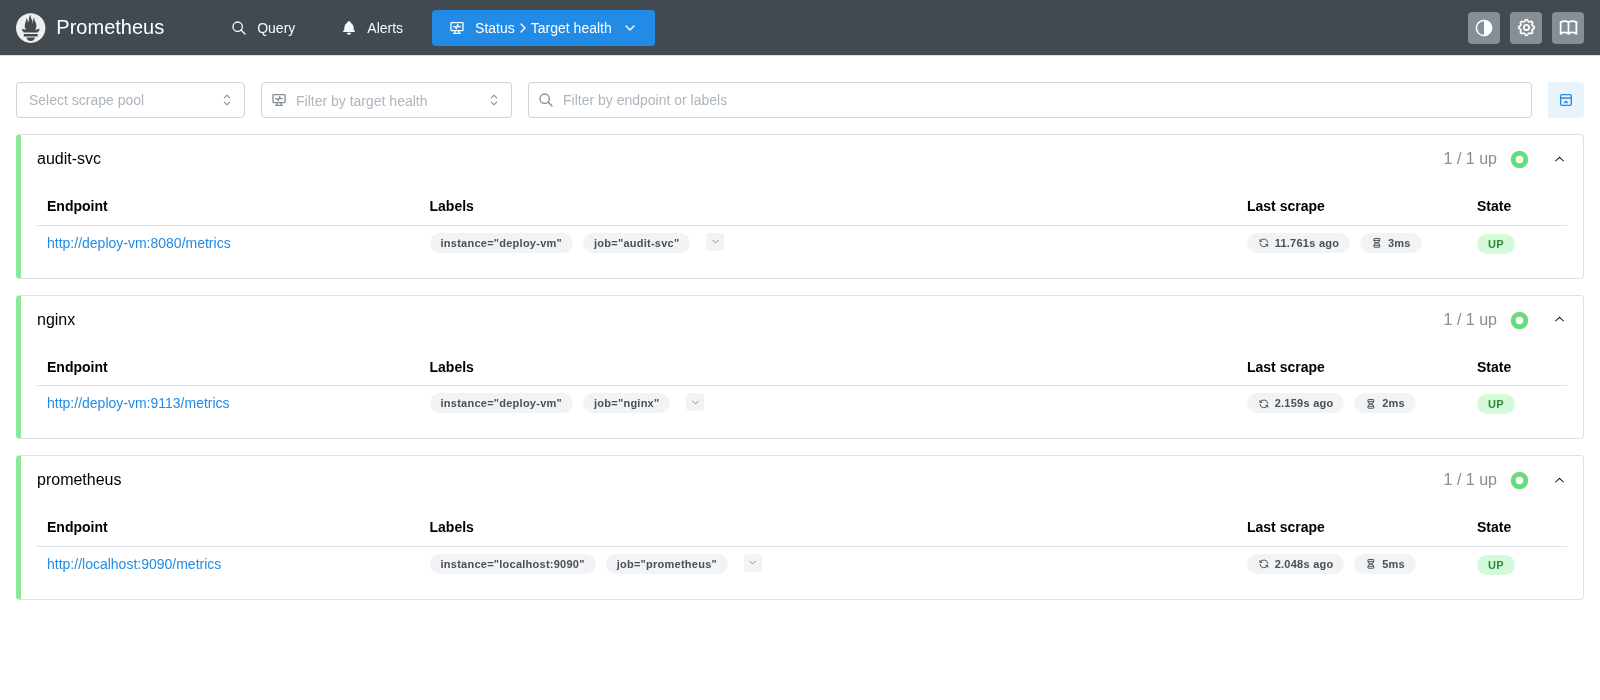


### Дашборд audit-svc - UP
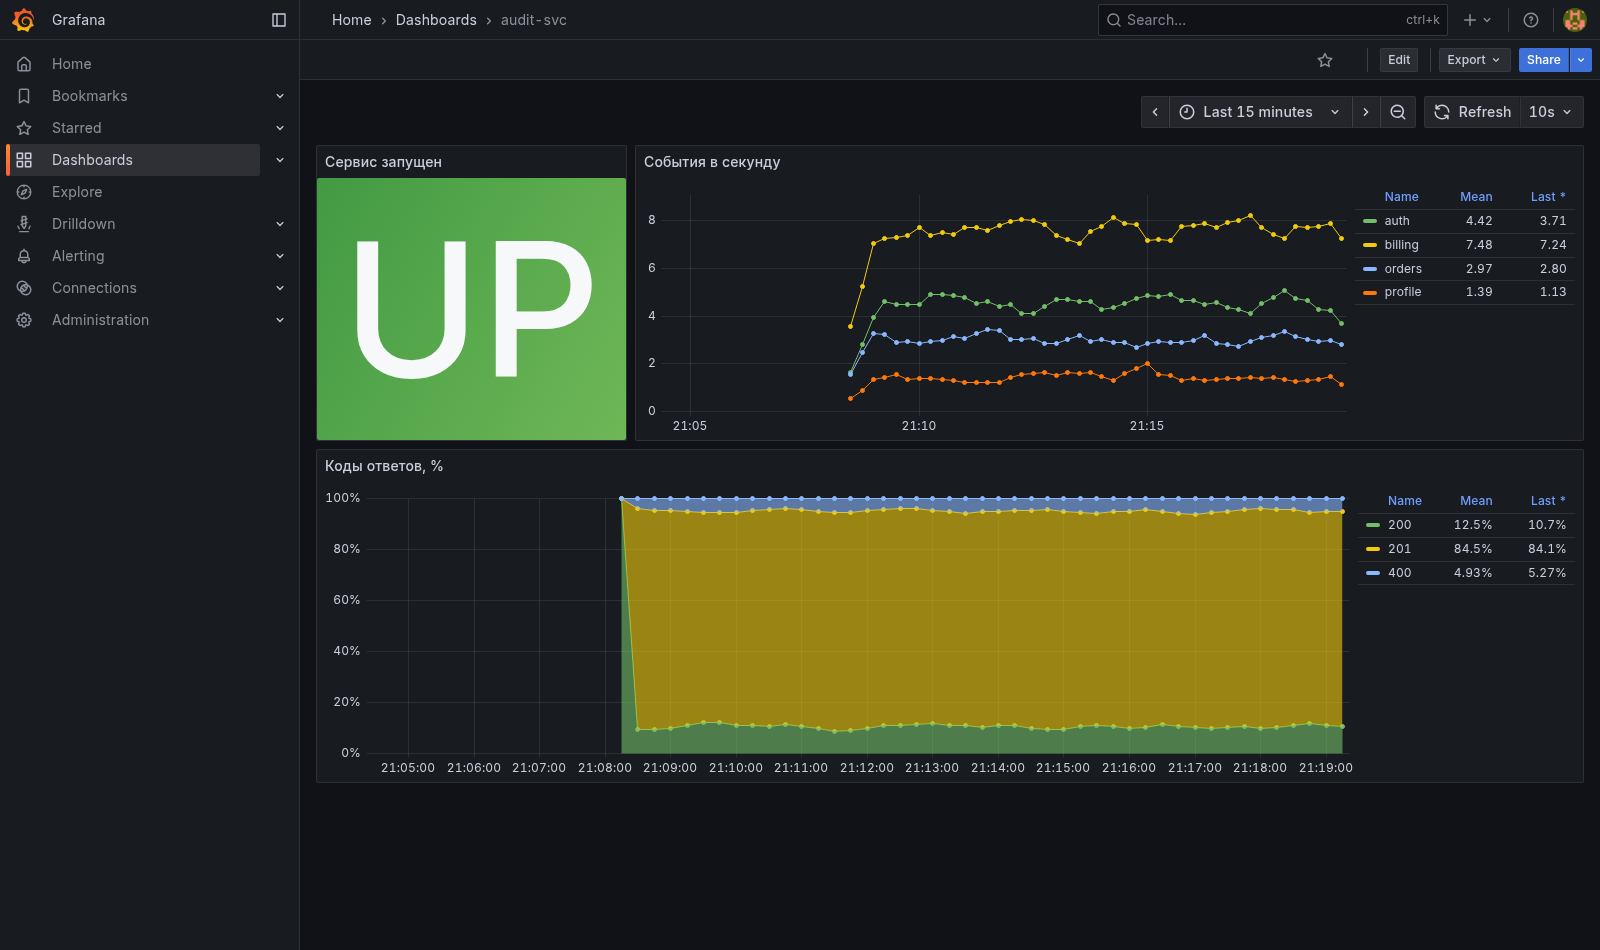


### Дашборд audit-svc - DOWN
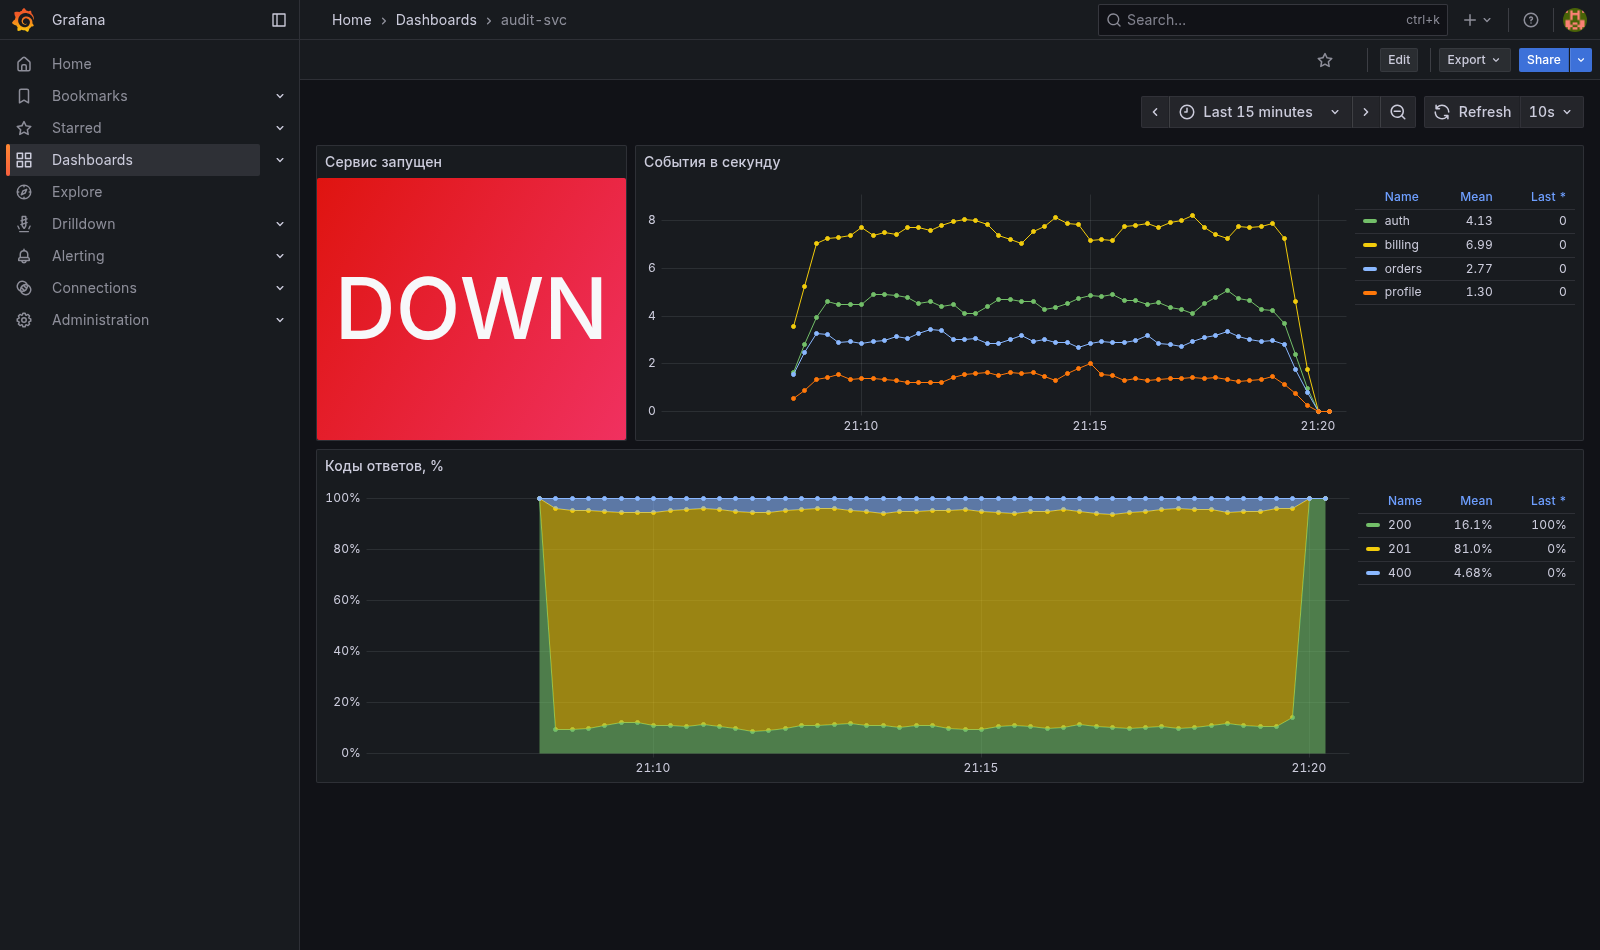


### Дашборд nginx
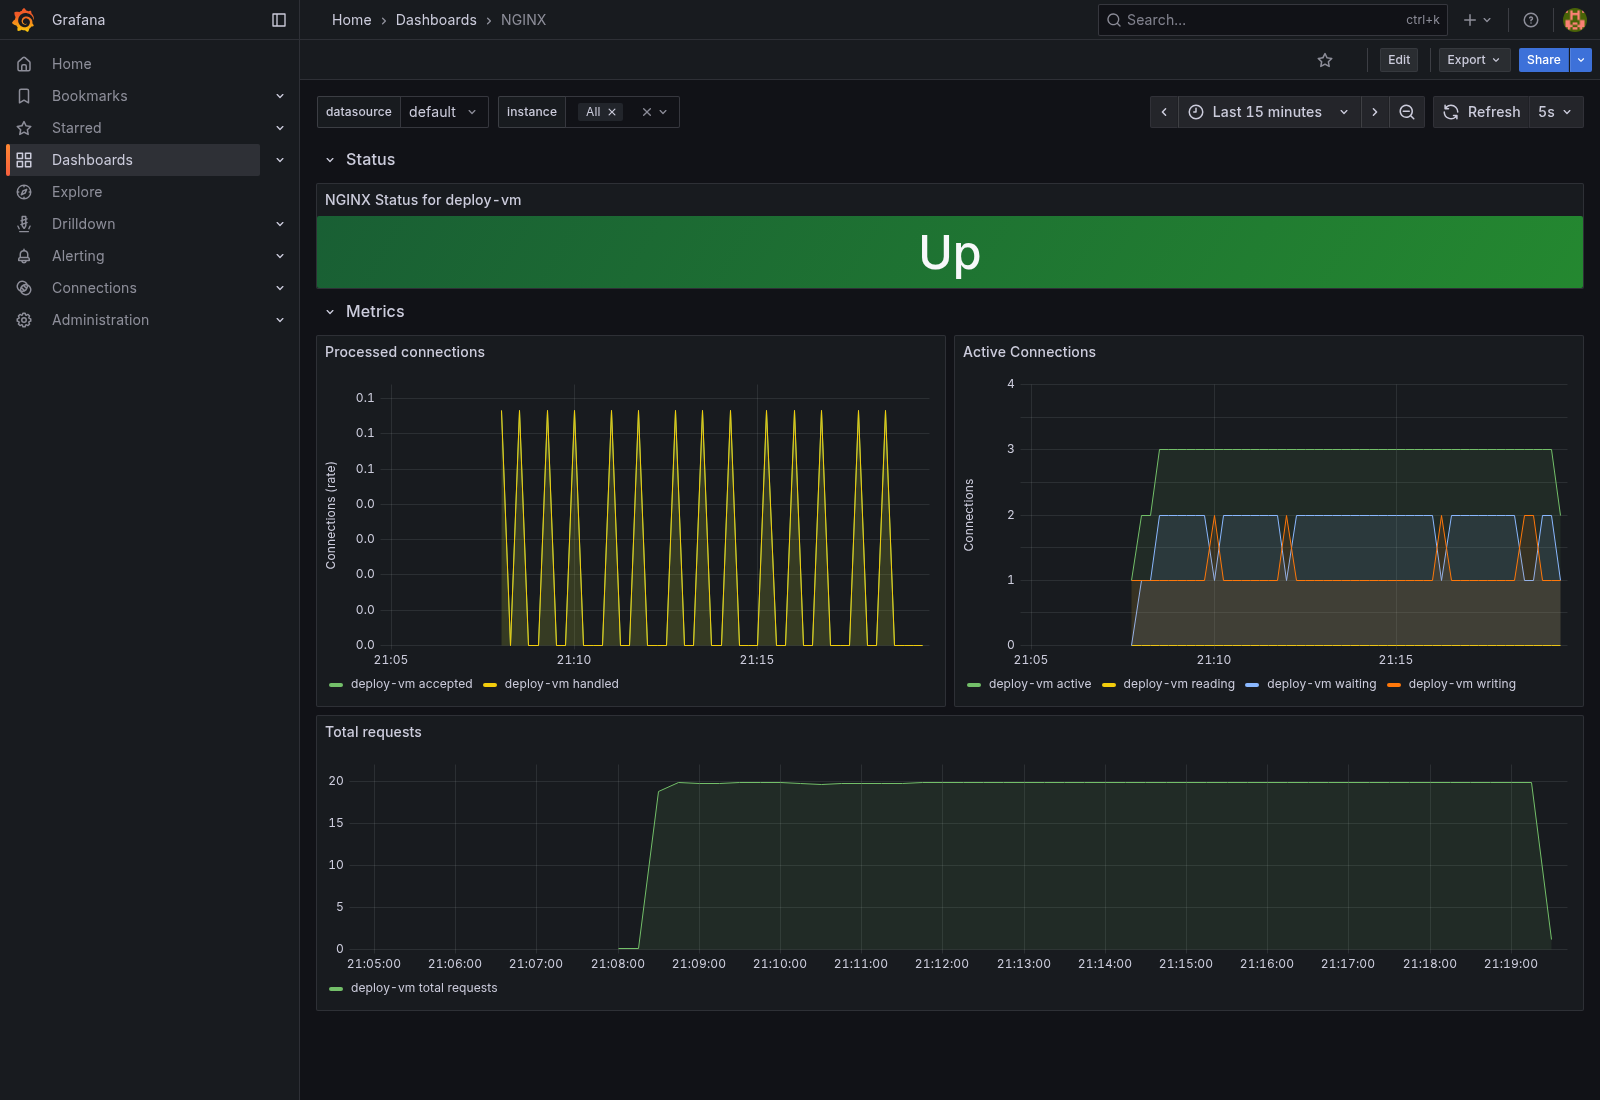
